In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('/content/customer_churn_sample.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head(15)

,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes
5,CUST-1006,Male,31,18,Basic,49.99,899.82,One Year,2,UPI,No
6,CUST-1007,Female,23,3,Basic,49.99,149.97,Month-to-Month,6,Credit Card,Yes
7,CUST-1008,Male,60,48,Enterprise,149.99,7199.52,Two Year,1,Bank Transfer,No
8,CUST-1009,Female,38,15,Pro,79.99,1199.85,One Year,2,Credit Card,No
9,CUST-1010,Male,27,4,Basic,49.99,199.96,Month-to-Month,4,UPI,Yes


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape:
(15, 11)

Column Names:
['CustomerID', 'Gender', 'Age', 'TenureMonths', 'SubscriptionType', 'MonthlyCharges', 'TotalCharges', 'ContractType', 'SupportTickets', 'PaymentMethod', 'Churn']

Data Types:
CustomerID           object
Gender               object
Age                   int64
TenureMonths          int64
SubscriptionType     object
MonthlyCharges      float64
TotalCharges        float64
ContractType         object
SupportTickets        int64
PaymentMethod        object
Churn                object
dtype: object


In [5]:
print(df.isnull().sum())

CustomerID          0
Gender              0
Age                 0
TenureMonths        0
SubscriptionType    0
MonthlyCharges      0
TotalCharges        0
ContractType        0
SupportTickets      0
PaymentMethod       0
Churn               0
dtype: int64


In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [7]:
df.describe()

,Age,TenureMonths,MonthlyCharges,TotalCharges,SupportTickets
count,15.000000,15.000000,15.000000,15.000000,15.000000
mean,39.066667,18.800000,84.656667,2088.478667,2.533333
std,11.392144,14.333776,42.739521,2407.365767,1.922300
min,23.000000,2.000000,49.990000,99.980000,0.000000
25%,30.000000,7.000000,49.990000,449.910000,1.000000
50%,38.000000,15.000000,79.990000,1099.780000,2.000000
75%,47.000000,27.000000,114.990000,3209.730000,4.000000
max,60.000000,48.000000,149.990000,7199.520000,6.000000


In [8]:
for col in df.select_dtypes(include=np.number).columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, ":", len(outliers), "outliers")

Age : 0 outliers
TenureMonths : 0 outliers
MonthlyCharges : 0 outliers
TotalCharges : 0 outliers
SupportTickets : 0 outliers


In [9]:
# Check unique customer IDs
print("Unique Customer IDs:",
      df['CustomerID'].is_unique)

# Check valid age
print("Invalid Age:",
      (df['Age'] <= 0).sum())

# Check valid tenure
print("Invalid Tenure:",
      (df['TenureMonths'] <= 0).sum())

# Check negative charges
print("Invalid Monthly Charges:",
      (df['MonthlyCharges'] < 0).sum())

print("Invalid Total Charges:",
      (df['TotalCharges'] < 0).sum())

# Check churn values
print("Churn Categories:",
      df['Churn'].unique())

# Verify total charges
expected = df['MonthlyCharges'] * df['TenureMonths']

print("Total Charges Match:",
      np.isclose(df['TotalCharges'], expected).all())

Unique Customer IDs: True
Invalid Age: 0
Invalid Tenure: 0
Invalid Monthly Charges: 0
Invalid Total Charges: 0
Churn Categories: ['Yes' 'No']
Total Charges Match: True


In [10]:
# Create a copy of original dataset
cleaned_df = df.copy()

# Remove duplicate records if any
cleaned_df = cleaned_df.drop_duplicates()

# Remove records with missing values if any
cleaned_df = cleaned_df.dropna()

# Save cleaned dataset
cleaned_df.to_csv(
    'cleaned_customer_churn.csv',
    index=False
)

print("Data cleaning completed!")
print("Original Shape:", df.shape)
print("Cleaned Shape:", cleaned_df.shape)

Data cleaning completed!
Original Shape: (15, 11)
Cleaned Shape: (15, 11)


In [11]:
from google.colab import files

files.download('cleaned_customer_churn.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Descriptive Statistics

print("Mean:")
print(cleaned_df.mean(numeric_only=True))

print("\nMedian:")
print(cleaned_df.median(numeric_only=True))

print("\nMinimum:")
print(cleaned_df.min(numeric_only=True))

print("\nMaximum:")
print(cleaned_df.max(numeric_only=True))

print("\nStandard Deviation:")
print(cleaned_df.std(numeric_only=True))

Mean:
Age                 39.066667
TenureMonths        18.800000
MonthlyCharges      84.656667
TotalCharges      2088.478667
SupportTickets       2.533333
dtype: float64

Median:
Age                 38.00
TenureMonths        15.00
MonthlyCharges      79.99
TotalCharges      1099.78
SupportTickets       2.00
dtype: float64

Minimum:
Age               23.00
TenureMonths       2.00
MonthlyCharges    49.99
TotalCharges      99.98
SupportTickets     0.00
dtype: float64

Maximum:
Age                 60.00
TenureMonths        48.00
MonthlyCharges     149.99
TotalCharges      7199.52
SupportTickets       6.00
dtype: float64

Standard Deviation:
Age                 11.392144
TenureMonths        14.333776
MonthlyCharges      42.739521
TotalCharges      2407.365767
SupportTickets       1.922300
dtype: float64


In [13]:
# Customer Churn Analysis

churn_count = cleaned_df['Churn'].value_counts()

print("Customer Churn Count:")
print(churn_count)

print("\nChurn Percentage:")
print(cleaned_df['Churn'].value_counts(normalize=True) * 100)

Customer Churn Count:
Churn
No     8
Yes    7
Name: count, dtype: int64

Churn Percentage:
Churn
No     53.333333
Yes    46.666667
Name: proportion, dtype: float64


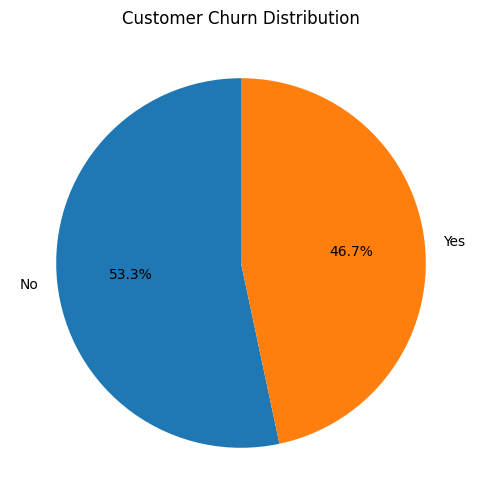

In [14]:
plt.figure(figsize=(6,6))

cleaned_df['Churn'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Churn Distribution')
plt.ylabel('')
plt.show()

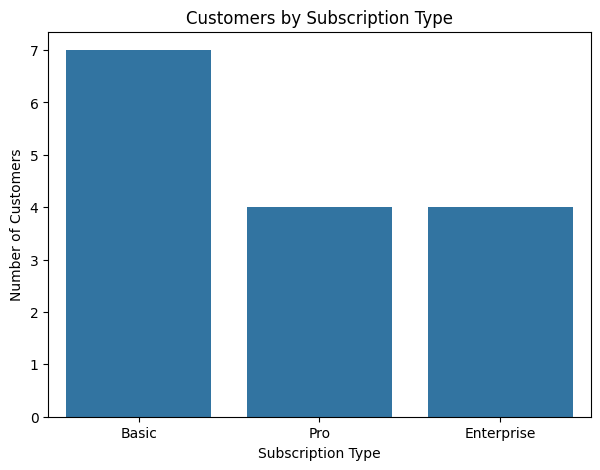

In [15]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=cleaned_df,
    x='SubscriptionType'
)

plt.title('Customers by Subscription Type')
plt.xlabel('Subscription Type')
plt.ylabel('Number of Customers')
plt.show()

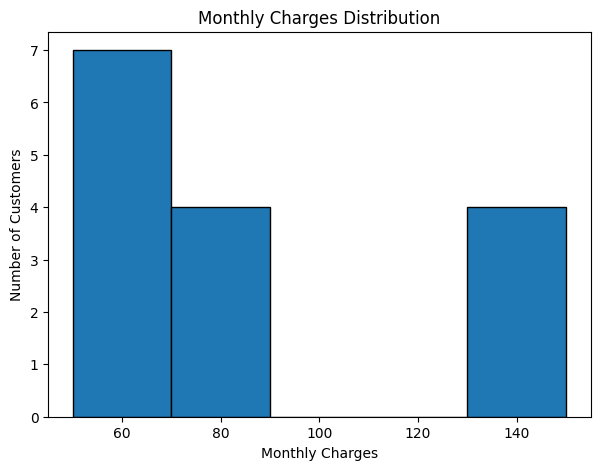

In [16]:
plt.figure(figsize=(7,5))

plt.hist(
    cleaned_df['MonthlyCharges'],
    bins=5,
    edgecolor='black'
)

plt.title('Monthly Charges Distribution')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')
plt.show()

### Exploratory Data Analysis – Observations

1. The dataset contains 15 customer records.
2. Out of 15 customers, 7 customers have churned and 8 customers have remained.
3. The customer churn rate is 46.67%.
4. Basic subscription has the highest number of customers (7).
5. Pro and Enterprise subscriptions have 4 customers each.
6. Month-to-Month contracts have the highest representation with 7 customers.
7. Monthly charges vary across customers depending on their subscription.

**Conclusion:** The exploratory analysis provides an initial understanding of customer distribution, subscription preferences and churn behaviour.